A Comparison between the Metropolis-Hastings, Wolff and Swendsen-Wang Algorithms on the 2D Ising Model

In [72]:
import importlib
import Algorithm_module as alg
importlib.reload(alg)
import Simulation_module as sim
importlib.reload(sim)
import Analysis_module as ana
importlib.reload(ana)
import numpy as np
import matplotlib.pyplot as plt

"""
Runtime of notebook < 20 seconds
"""
BETAJ_CRIT = 0.4407 # to 4 d.p.

<h1>1 Introduction</h1>




This investigation focuses on the application of three algorithms (Metropolis-Hastings, Wolff, and Swendsen-Wang) to study the behaviour of lattice systems (based on the 2D Ising Model) of various sizes and at different temperatures, with a particular focus on critical slowing down and autocorrelation near criticality. The Metropolis-Hastings algorithm generates configurations of the system by iteratively proposing random changes to the spin orientations. The acceptance probability of each move depends on the change in energy, which ensures that the system samples states according to the Boltzmann distribution. While this method is straightforward and widely used, it suffers from critical slowing down: a phenomenon where the system's autocorrelation time diverges near the phase transition, causing the system to take much longer to equilibrate.

Autocorrelation time is a measure of the correlation between values of a quantity (such as magnetisation in a physical system) at different time steps during a simulation. It quantifies how long it takes for the system to "forget" its previous state. In effect, it measures how long it takes for the system to effectively explore new configurations, independent of earlier states. If the autocorrelation time is long, it means that successive samples from the simulation are highly correlated, and the system is "stuck" in similar configurations for extended periods before exploring new states. Therefore, minimising the autocorrelation time is crucial for obtaining reliable and statistically independent samples, which is necessary for accurate estimation of physical quantities in Monte Carlo simulations.

The Wolff algorithm and Swendsen-Wang algorithm are cluster algorithms that attempt to reduce this issue by flipping clusters of spins simultaneously rather than individual spins. Both algorithms work by identifying connected groups of spins that are aligned and flipping them all at once, which leads to more significant changes in the system in a single step. This greatly reduces the autocorrelation time and accelerates the equilibration process, particularly near the critical temperature.

Wolff algorithm: In this approach, the algorithm uses a single spin as a seed and then grows a cluster of spins that are correlated with the seed. This cluster is then flipped as a whole. The Wolff algorithm is particularly efficient for systems near the critical point because it significantly reduces the number of updates required to move between important configurations.

Swendsen-Wang algorithm: This algorithm operates similarly to the Wolff algorithm, but instead of growing clusters from a single seed, it identifies all pairs of neighbouring spins with similar values (either both up or both down) and flips them simultaneously. This method also improves sampling efficiency by reducing autocorrelation.


The simulations were run on lattice systems of different sizes to study finite-size effects and critical slowing down. examining the autocorrelation function of the magnitude of the mean magnetisation at different times with the aim of understanding how the cluster algorithms (Wolff and Swendsen-Wang) outperform the Metropolis algorithm in reducing critical slowing down. 




<h1>2 Method</h1>

This describes the implementation of the Metropolis-Hastings, Wolff and Swendsen-Wang algorithms, how the data was collected and analysed as well as various verifications that the algorithms were performing as intended. These checks already begin to illustrate the differences between the algorithms.

<h2>2.1 Algorithm implementation</h2>

<h3>2.1.1 Metropolis-Hastings algorithm</h3>
For each sweep:

1. Choose a spin at random.

2. Compute energy change ΔE if the spin is flipped.

3. Accept flip with probability: $P = \min(1, e^{-\beta \Delta E})$.

4. Repeat for total number of sites per sweep.

Steps 1-4 are implemented with the compute_deltaE(), metropolis_hastings() and normalised_step() functions from the Algorithm module 

<h3>2.1.2 Wolff algorithm </h3>

For each sweep:

1. Choose a random "seed" spin.

2. Grow a cluster by adding neighbouring aligned spins with probability: $P_{\text{add}} = 1 - e^{-2\beta J}$ to maintain detailed balance.

3. Repeat step 2 recursively for all newly added spins.

4. Flip the entire cluster.

Steps 1–4 are implemented with the wolff() function from the Algorithm module.

<h3>2.1.3 Swendsen-Wang algorithm </h3>

For each sweep:

1. Identify all neighbouring spin pairs with the same orientation.

2. For each such pair, form a bond with probability:$P_{\text{bond}} = 1 - e^{-2\beta J}$ to maintain detailed balance.

3. Form clusters of connected spins using the bonds.

4. Flip each cluster independently with 50% probability.

Steps 1–4 are implemented with the build_clusters() and swendsen_wang() functions from the Algorithm module.

<h2> 2.2 Data analysis</h2>
<h3>2.2.1 Measuring data</h3>

All the data used in the results section was collected simultaneously by executing the run_simulation() function from the simulation module. This returned an array of the mean magnetisation at each sweep, an array of the (normalised) autocorrelation at each sweep, a list of the average time per sweep and the acceptance rate (for Metropolis-Hastings) or the average cluster size (for the cluster algorithms) and the respective errors after averaging over five runs each. This data was saved in the accompanying cache folder as .npz files for easy retrieval when plotting graphs in this notebook.


<h3>2.2.2 Determining autocorrelation time </h3>

Autocorrelation time was determined by fitting the autocorrelation time series for each simulation to an exponential decay curve of the form $e^{-t/\tau}$ where $\tau$ is the autocorrelation time and t is the time in number of sweeps. For the autocorrelation calculations, I discarded the initial non-equilibrated data ($\approx$ first 20%) based on preliminary tests of convergence.

Pure timing benchmarks are performed over the entire simulation and are averaged per sweep.


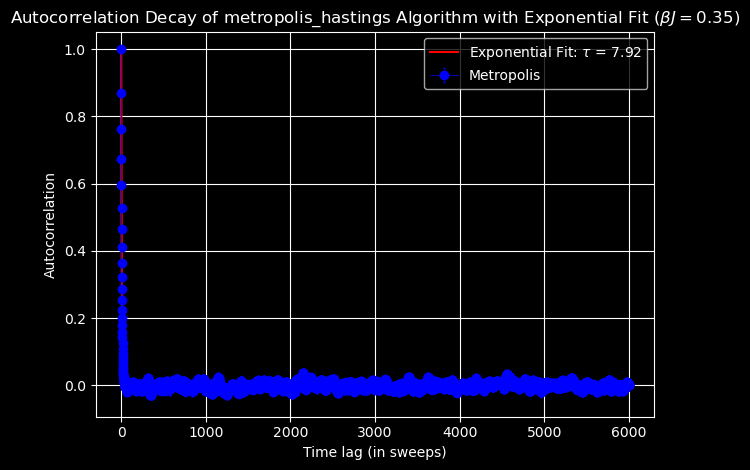

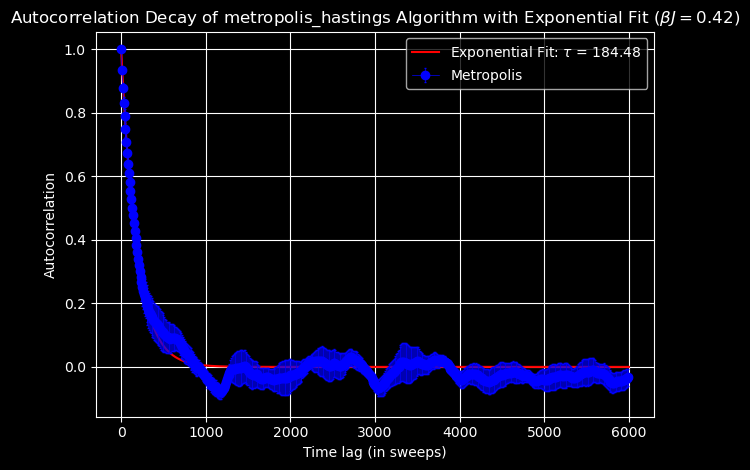

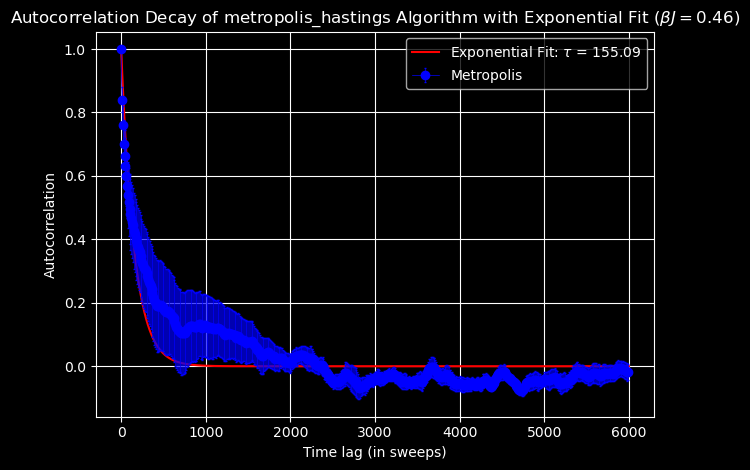

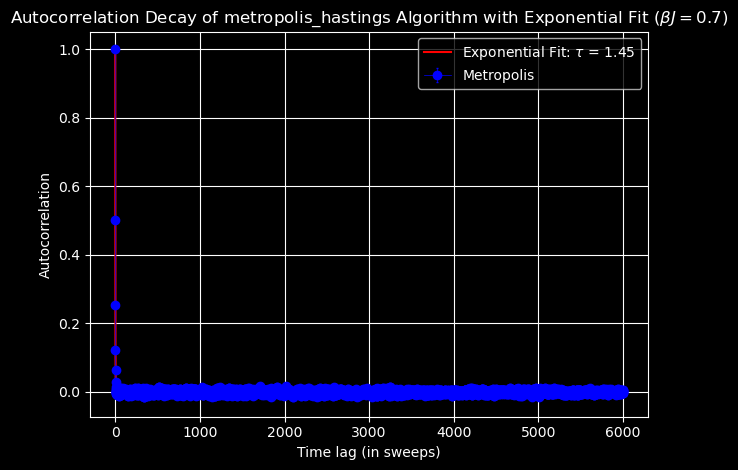

In [73]:
importlib.reload(ana)
# MH
betaJs = [0.35,0.42,0.46,0.7]
for betaj in betaJs:
    autocorr, autoerr= sim.run_simulation(
        128, betaj, alg.metropolis_hastings, 15000
    )[2:4]
    tau = ana.find_autocorrelation_time(autocorr)
    if tau < 10:
        spacing = 1
    else: 
        spacing = 10
    ana.plot_autocorr(betaj,alg.metropolis_hastings,autocorr,autoerr,spacing)




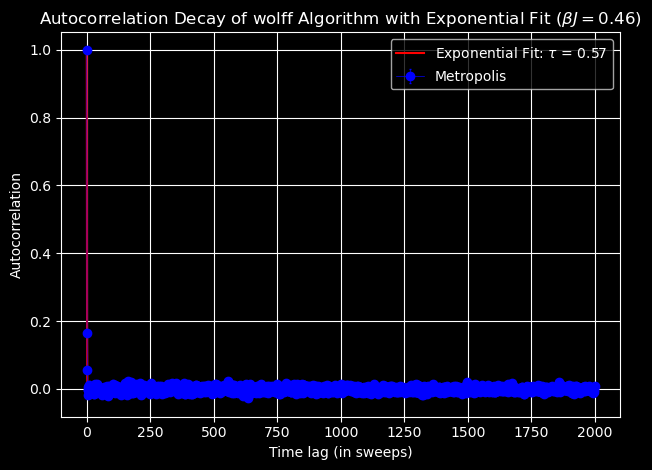

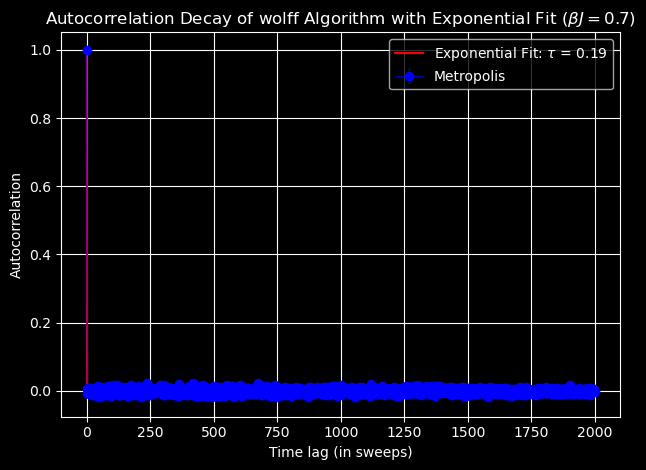

In [74]:
# Wolff
betaJs = [0.46,0.7]
for betaj in betaJs:
    autocorr, autoerr = sim.run_simulation(128, betaj, alg.wolff, 15000)[
        2:4
    ]
    tau = ana.find_autocorrelation_time(autocorr)

    ana.plot_autocorr(betaj, alg.wolff, autocorr, autoerr, 1)

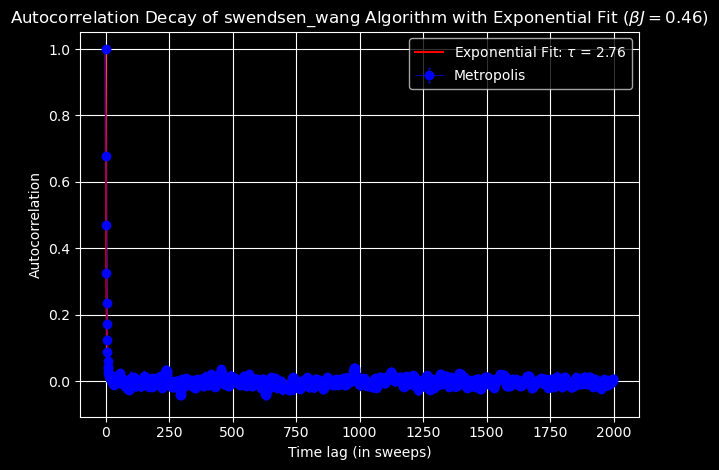

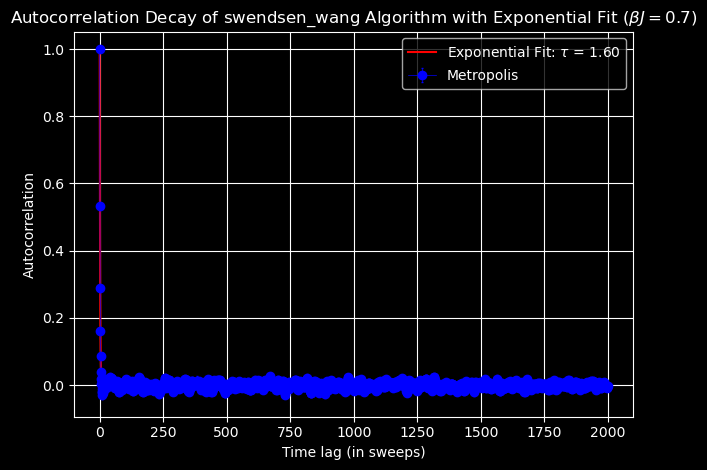

In [75]:
# SW
for betaj in betaJs:
    autocorr, autoerr = sim.run_simulation(128, betaj, alg.swendsen_wang, 15000)[2:4]
    tau = ana.find_autocorrelation_time(autocorr)

    ana.plot_autocorr(betaj, alg.swendsen_wang, autocorr, autoerr, 1)

<h2> 2.3 Algorithm validation </h2>

<h3>2.3.1 Convergence times</h3>
An important test of convergence is how quickly the algorithms reach equilibrium starting from different initial conditions, that is, disordered and ordered initial configurations. If the different lattices take a long time to overlap, it suggests that the algorithm used struggles to explore the phase space, getting stuck in metastable configurations. Below, the magnetisations against sweep number are plotted for the three algorithms and for high, low and critical temperature.

As can be seen by the varying number of sweeps per simulation, the Metropolis-Hastings converges much more slowly than the cluster algorithms, as expected. This validates the decision to run all the Metropolis-Hastings simulations for longer than the cluster algorithms to ensure that enough equilibrium data is obtained for further analysis.


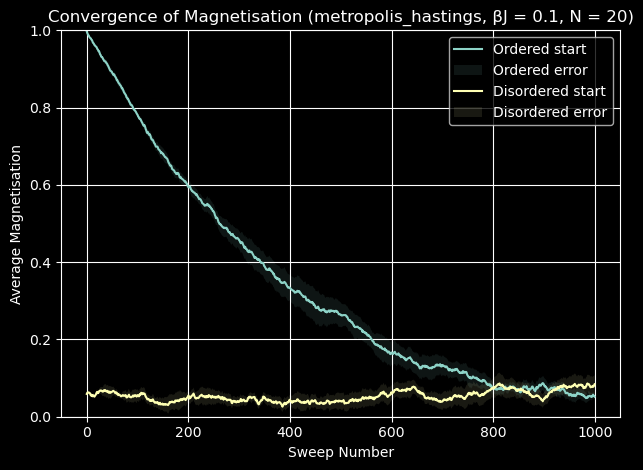

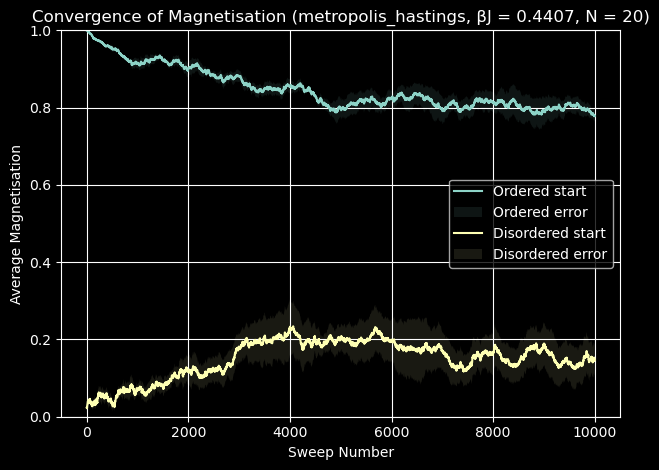

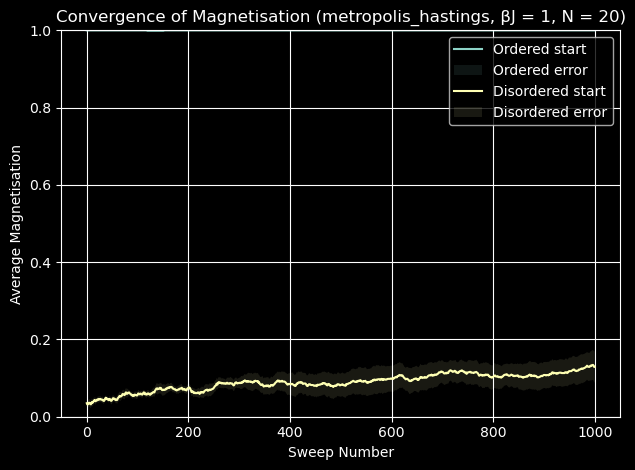

In [76]:
# For Metropolis-Hastings
import Convergence as cv
importlib.reload(cv)

lattice_size = 20
betaJ = 0.1
sweeps = 1000

# Different sweep values since convergence near Tc very slow compared to at high T
plt.figure()
cv.plot_convergence(alg.metropolis_hastings,sweeps,lattice_size,betaJ)

betaJ = BETAJ_CRIT
sweeps = 10000

plt.figure()
cv.plot_convergence(alg.metropolis_hastings, sweeps, lattice_size, betaJ)

betaJ = 1
sweeps = 1000

plt.figure()
cv.plot_convergence(alg.metropolis_hastings, sweeps, lattice_size, betaJ)

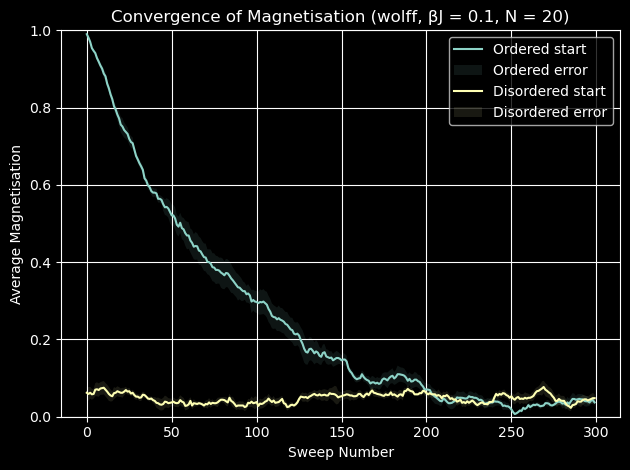

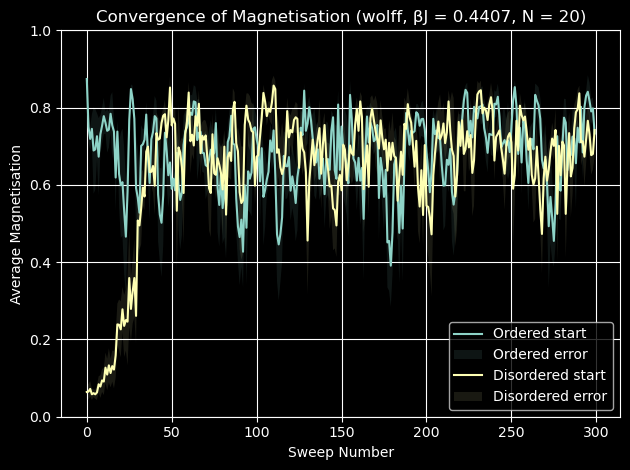

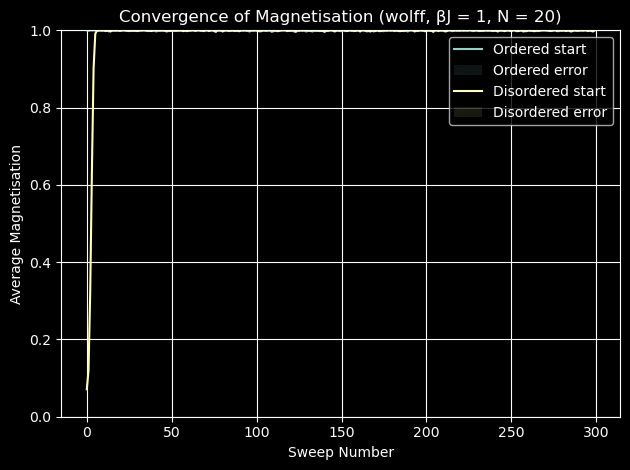

In [77]:
# For Wolff

lattice_size = 20
betaJs = [0.1, BETAJ_CRIT, 1]
sweeps = 300


for betaJ in betaJs:
    plt.figure()
    cv.plot_convergence(alg.wolff, sweeps, lattice_size, betaJ)

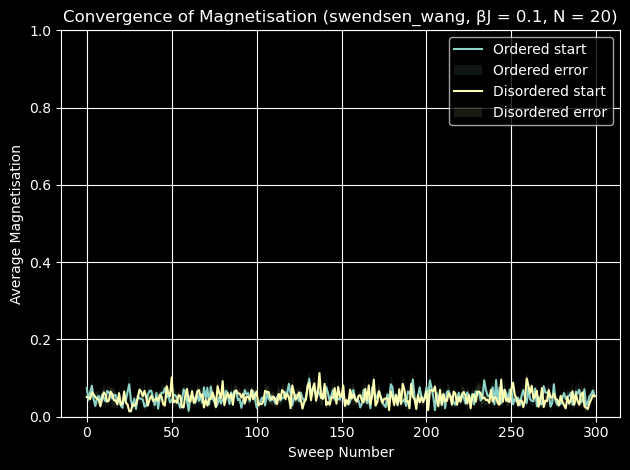

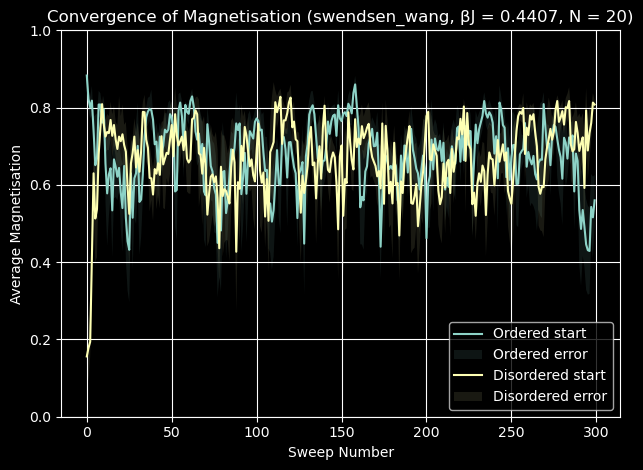

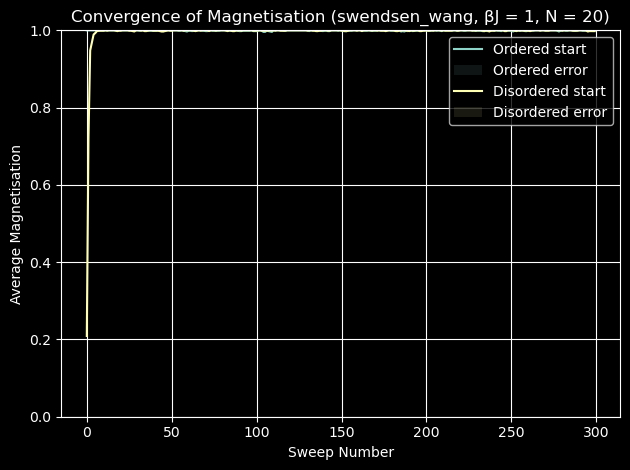

In [78]:
# For Swendsen-Wang

for betaJ in betaJs:
    plt.figure()
    cv.plot_convergence(alg.swendsen_wang, sweeps, lattice_size, betaJ)
    

<h3>2.3.2 Cluster size distribution</h3>

As another verification that the cluster algorithms were working as intended, histograms of the cluster size distributions at high, low and critical temperature were plotted for the Wolff and Swendsen-Wang algorithms on 50x50 lattices, along with the mean cluster sizes. Only 500 sweeps (2000 sweeps for critical temperature) were used to minimise runtime, but the distributions were already as expected: mean cluster sizes on the order of one for high temperature (sharp peak since disordered phase with not many aligned spin neighbours), mean cluster sizes on the order of the total number of sites for low temeperature for Wolff (sharp peak since practically all aligned spins) and a broad peak of cluster sizes at the critical temperature, perhaps indicating scale invariance. For the Swendsen-Wang algorithm, the returned cluster lengths are only averages since the algorithm splits the whole lattice into clusters as opposed to a single cluster like in the Wolff algorithm. In any case, the average cluster size increased with betaJ, which is the expected behaviour.

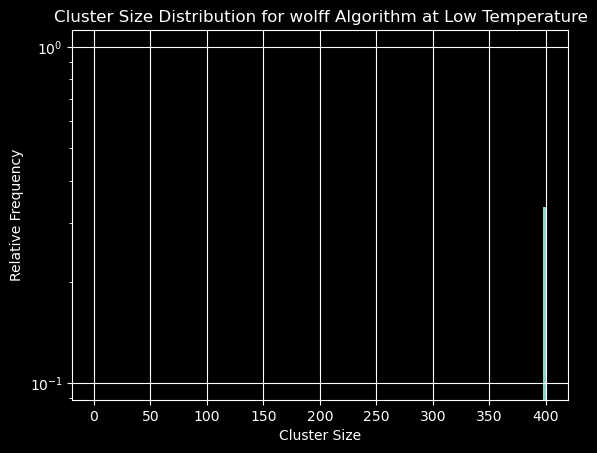

Average cluster size: 400.0


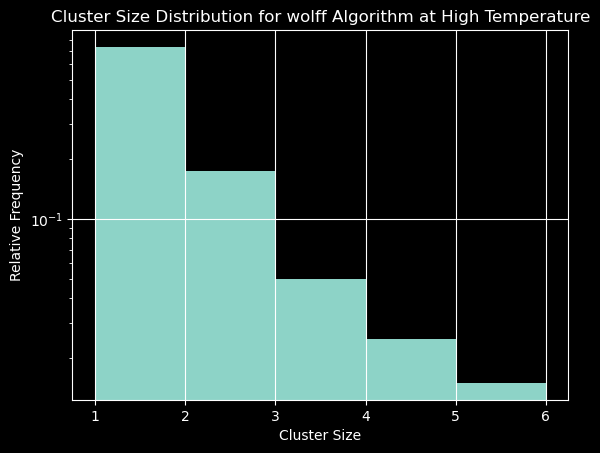

Average cluster size: 1.4125


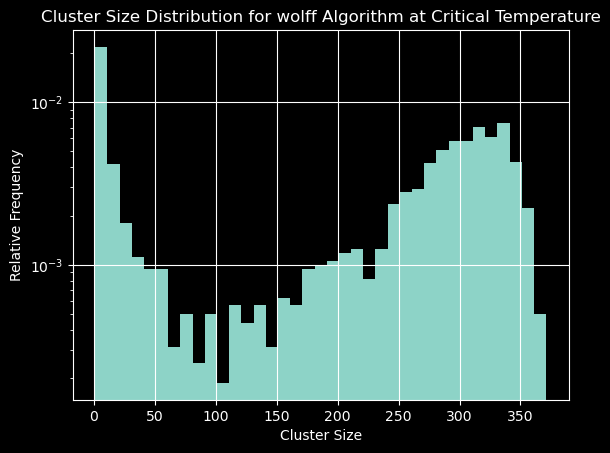

Average cluster size: 198.139375


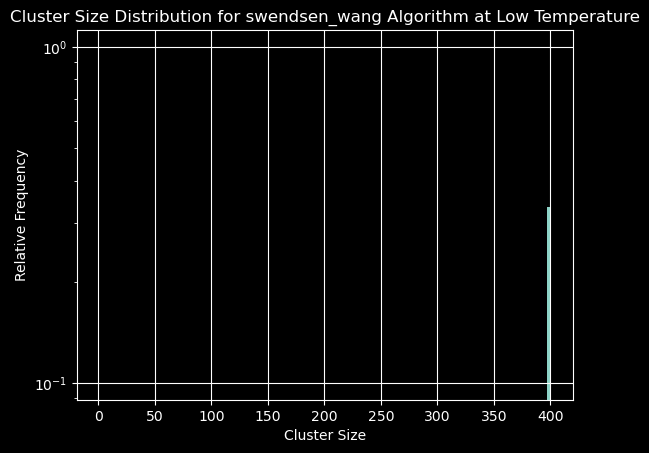

Average cluster size: 400.0


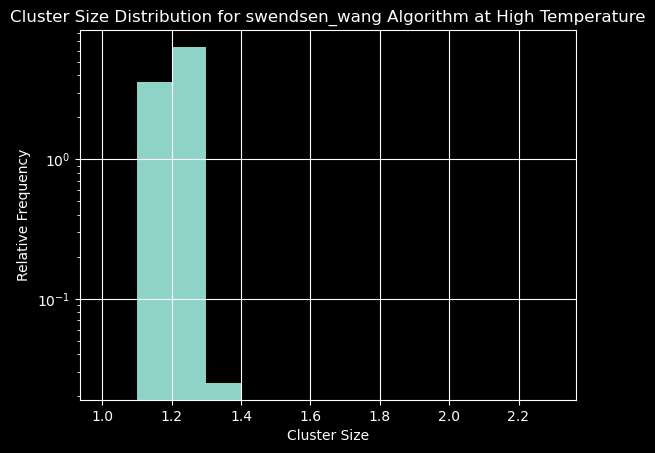

Average cluster size: 1.2124077204578325


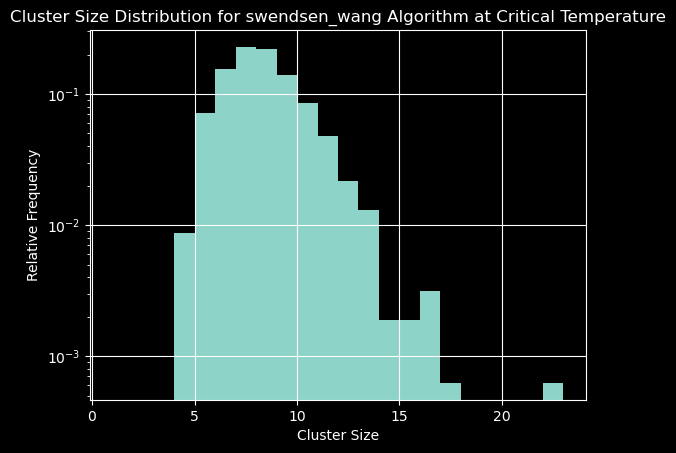

Average cluster size: 8.338244806696643


In [79]:
import Cluster_accept_plots as cp

importlib.reload(cp)


betaJ_range = np.concatenate(
    [
        np.linspace(0.2, 0.42, 4),
        [
            BETAJ_CRIT - 0.01,
            BETAJ_CRIT,
            BETAJ_CRIT + 0.01,
        ],  # Finer selection of values near betaJ_crit since metrics vary quickly in this region
        np.linspace(0.46, 0.70, 4),
    ]
)

lattice_size = 20
sweeps = 500
width = 1


# Wolff
cp.plot_histogram(sweeps,lattice_size,alg.wolff,BETAJ_CRIT*5,"Low",width*3)
cp.plot_histogram(sweeps, lattice_size, alg.wolff, BETAJ_CRIT/5, "High", width)
cp.plot_histogram(int(sweeps*4), lattice_size, alg.wolff, BETAJ_CRIT, "Critical", width*10) # To get more representative distribution at criticality

# # Swendsen-Wang

cp.plot_histogram(sweeps, lattice_size, alg.swendsen_wang, BETAJ_CRIT * 5, "Low", width*3)
cp.plot_histogram(sweeps, lattice_size, alg.swendsen_wang, BETAJ_CRIT / 5, "High", width*0.1)
cp.plot_histogram(
    int(sweeps * 4), lattice_size, alg.swendsen_wang, BETAJ_CRIT, "Critical", width 
)  # To get more representative distribution at criticality

This behaviour is even more clearly observed using a line plot of average cluster size against $\beta J$. Dashed line at $\beta_{crit} J$ to demonstrate phase transition.

NB Swendsen-Wang exhibits a gradual increase in cluster size since, again, the whole lattice is partitioned into clusters, diluting the value for average cluster size

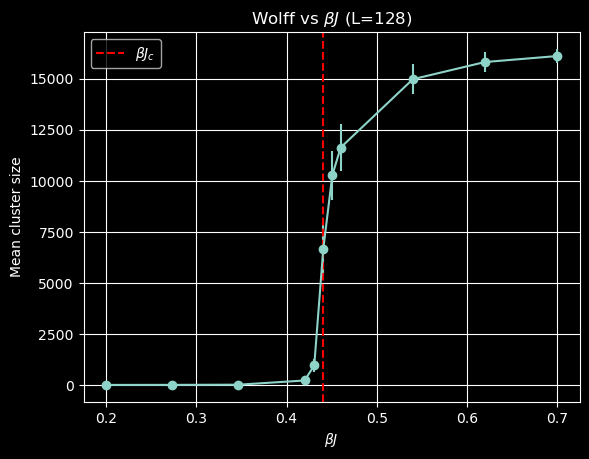

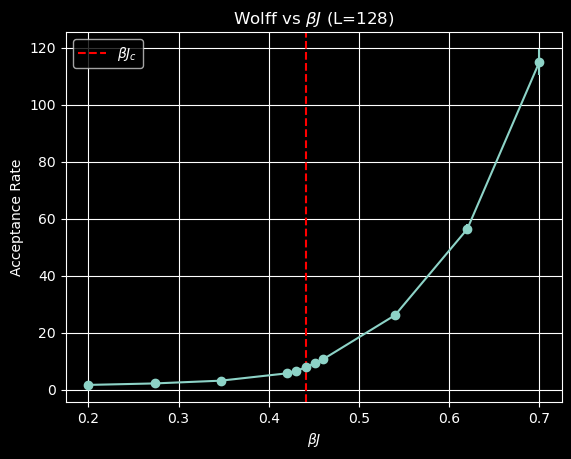

In [80]:
lattice_size = 128
cp.cluster_plot(betaJ_range, lattice_size)

<h3>2.3.3 Acceptance rate at different temperatures</h3>

The analogous quantity for the Metropolis-Hastings algorithm is the acceptance rate of proposed flips. Below, the plot shows that acceptance rate is higher at high temperature (low $\beta J$) than at low temperature. This is expected since the probability of acceptance depends on the Boltzmann distribution, and it should be easier to explore states at higher temperatures. However, the peak of the acceptance ratio is around criticality. This is likely because in this region, there are big fluctuations in magnetisation since this is the boundary between the ordered (m=1) and disordered (m=0) phases, meaning that proposed changes with bigger changes in energy are more likely to be accepted.




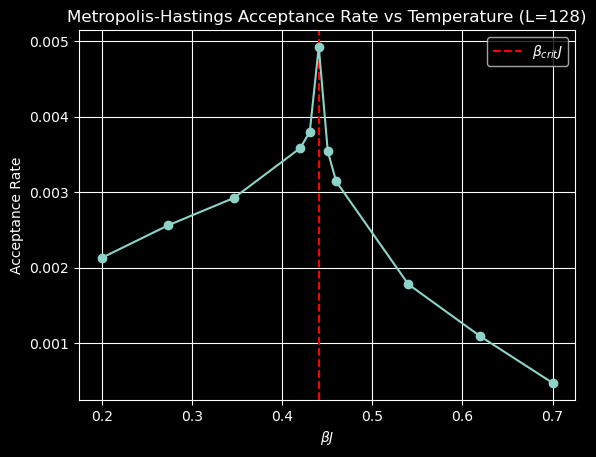

In [81]:
cp.accept_plot(betaJ_range, lattice_size)

<h1>3 Results</h1>

In this section, the results of the simulations are presented and analysed. We compare the performance of the three algorithms, highlighting the impact of critical slowing down and the improvements offered by the cluster algorithms in reducing autocorrelation times. Perfomance scaling with lattice size is also considered.

<h2>3.1 The Onsager Solution to the 2D Ising Model</h2>



The Onsager solution provides an exact analytical result for the 2D Ising model with no external magnetic field, solved by Lars Onsager in 1944. 

The system undergoes a second-order phase transition at the critical inverse temperature (setting J = 1):

$$
\beta_c J = \frac{1}{2} \ln(1 + \sqrt{2}) \approx 0.4407 
$$ 

Below this temperature, the system spontaneously magnetises even without an external field.

For temperatures below $T_c$ (above $\beta_{crit} J$), the spontaneous magnetisation is:

$$
M(\beta J) = \left[ 1 - \sinh^{-4}(2\beta J) \right]^{1/8}
$$

This vanishes continuously as $T$ tends to $T_c$, as expected for a second-order phase transition.

Comparing the plots of the magnetisations against inverse generated by the three algorithms checked if the algorithms produce accurate values of the magnetisation, validating the data produced. The erroneous value at $\beta J = 0.62$ measured using the Metropolis-Hastings algorithm was puzzling - especially since there were five runs of each simulation and the other algorithms performed fine - but unfortunately, time constraints prevented a rerun of that particular data point. The anomaly was ignored in the subsequent analysis.

[0.2        0.27333333 0.34666667 0.42       0.4307     0.4407
 0.4507     0.46       0.54       0.62       0.7       ]


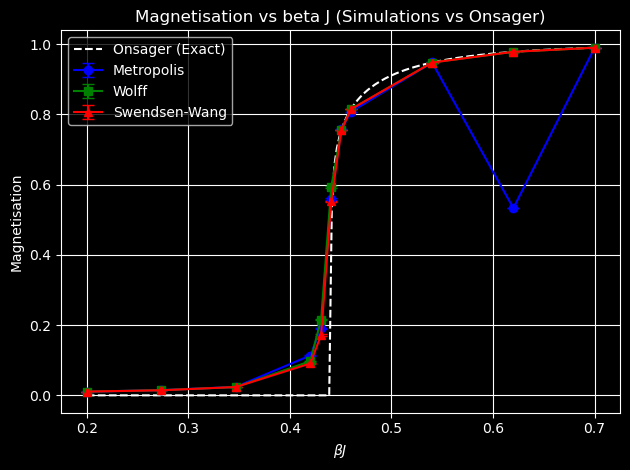

In [82]:
import Onsager as Lars
importlib.reload(Lars)

betaJ_range = np.concatenate(
    [
        np.linspace(0.2, 0.42, 4),
        [
            BETAJ_CRIT - 0.01,
            BETAJ_CRIT,
            BETAJ_CRIT + 0.01,
        ],  # Finer selection of values near betaJ_crit since metrics vary quickly in this region
        np.linspace(0.46, 0.70, 4),
    ]
)
print(betaJ_range)
Lars.Onsager_plot(betaJ_range)

<h2>3.2 Critical slow down analysis</h2>


/Users/theoneandonly/github-classroom/Part-II-Computational-Physics/computing-project-mh2167/Analysis_module.py:47: RuntimeWarning: overflow encountered in exp
  return A * np.exp(-t / tau)


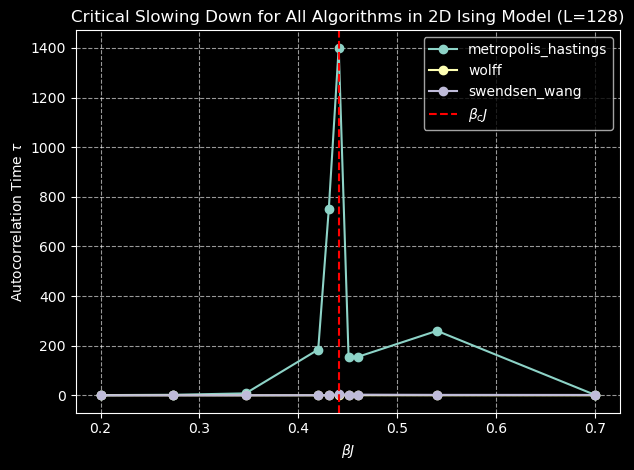

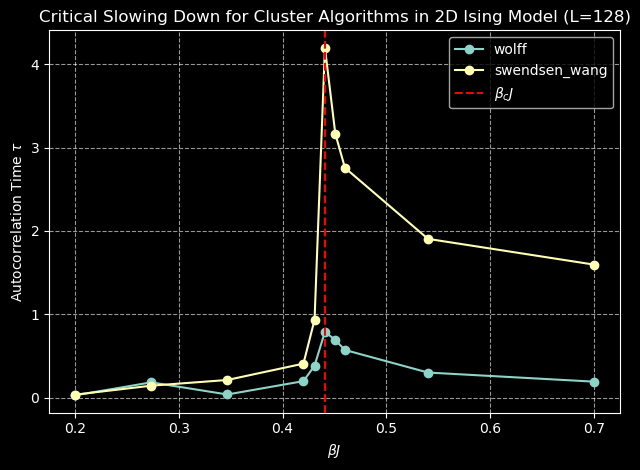

In [83]:
import CSD_plots as csd
importlib.reload(csd)

csd.plot_all()
csd.cluster_plot()

<h2>3.3 Dynamic critical exponent analysis</h2>



Running simulation for L = 16
Running simulation for L = 32
Running simulation for L = 64
Running simulation for L = 128


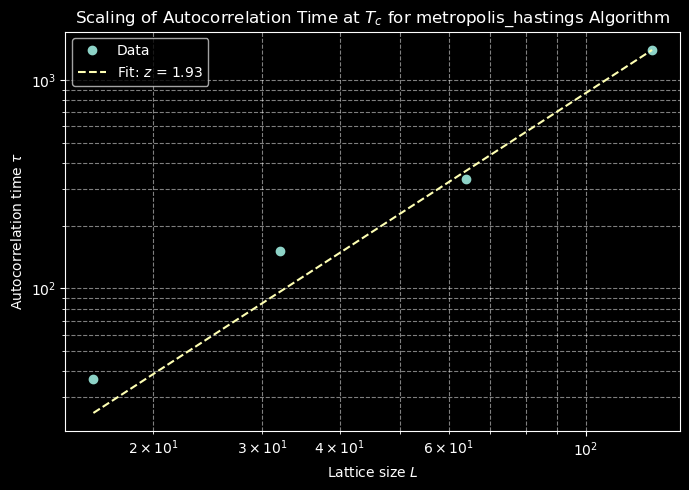

Running simulation for L = 16
Running simulation for L = 32
Running simulation for L = 64
Running simulation for L = 128


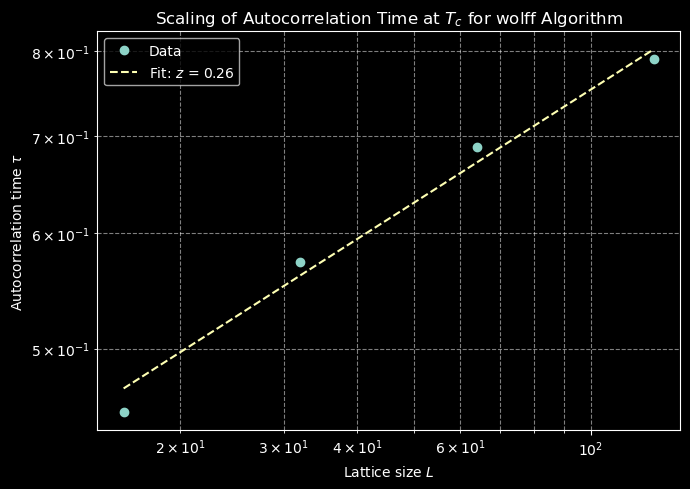

Running simulation for L = 16
Running simulation for L = 32
Running simulation for L = 64
Running simulation for L = 128


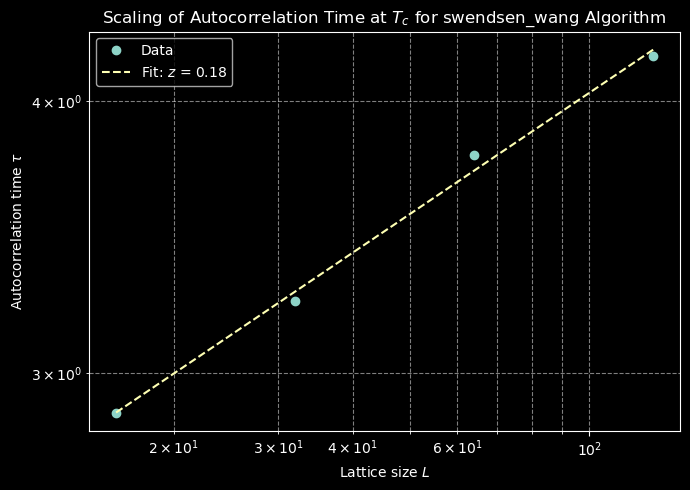

In [84]:
import Power_plot as pwr
importlib.reload(pwr)
lattice_sizes =  [16,32 ,64, 128]

pwr.power_plot(lattice_sizes,alg.metropolis_hastings)
pwr.power_plot(lattice_sizes, alg.wolff)
pwr.power_plot(lattice_sizes, alg.swendsen_wang)

<h2>3.4 Performance scaling with lattice size</h2>



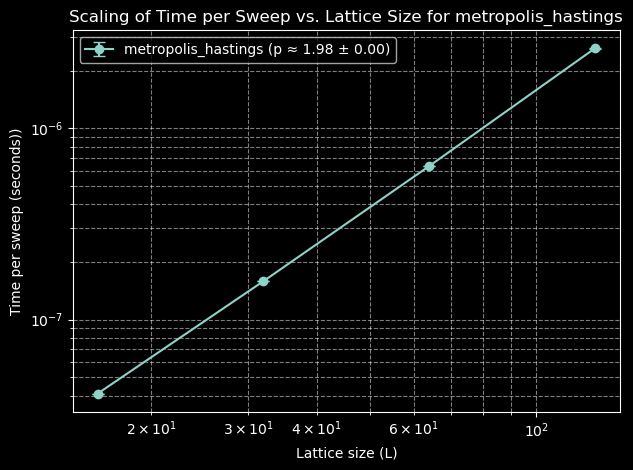

Fitted exponent (metropolis_hastings): p = 1.981 ± 0.001


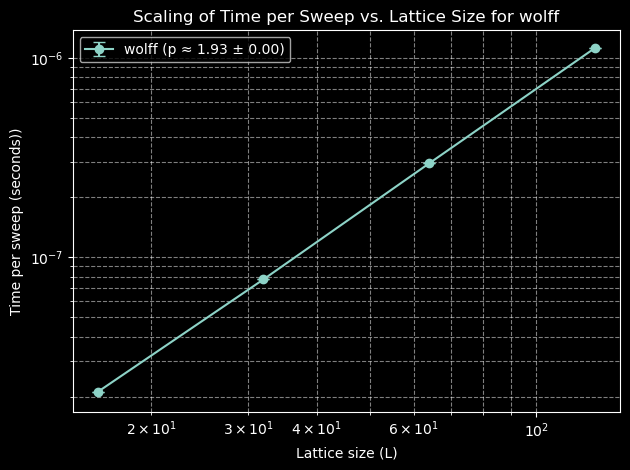

Fitted exponent (wolff): p = 1.929 ± 0.001


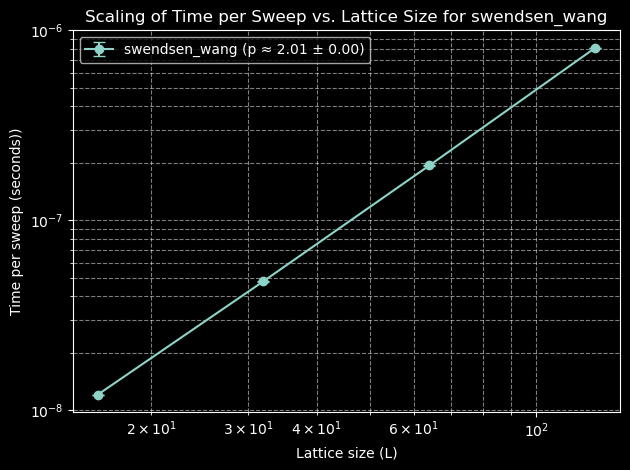

Fitted exponent (swendsen_wang): p = 2.011 ± 0.001


In [85]:
import Complexity as plx
importlib.reload(plx)

plx.plot_complexity(lattice_sizes,alg.metropolis_hastings)
plx.plot_complexity(lattice_sizes, alg.wolff)
plx.plot_complexity(lattice_sizes, alg.swendsen_wang)

<h1>4 Discussion</h1>
<h2>4.1 Interpretation of results</h2>
<h3>4.1.1 Critical slowing down</h3>

It is clear from the plot showing critical slowing down that the cluster algorithms offer a massive reduction in autocorrelation times near the critical temperature (roughly three orders of magnitude), which is in agreement with the expected result. The corresponding cluster plot clearly shows that the Wolff algorithm performed better than the Swendsen-Wang (peak $\tau_{max} \approx 1$ and 4 respectively), which agrees with the literature [1]. It is worth noting that the high $\beta J$ tails of the plots have higher autocorrelation times than the low tails. This is perhaps because in the ordered phase, the flip probability is low, so most proposed changes are rejected, slowing down fluctuations. This makes the system take longer to decorrelate and produce independent samples.

<h3>4.1.2 Estimation of dynamic critical exponents</h3>

The dynamic critical exponents determined for the algorithms were: (Metropolis-Hastings,1.93), (Wolff,0.26) and (Swendsen-Wang,0.18). While the first and last values were both lower than values in the literature, the Wolff exponent obtained was in good agreement with the values sourced from literature. The literature values were (2.167 ± 0.001), (0.25 ± 0.01) and (0.25 ± 0.01) respectively according to [2]. It is possible that finite size effects were to blame for the underestimates. Also, since the normalised sweep for the Wolff algorithm was only roughly the total number of sites, it is possible that this had an effect on its accuracy.

<h3>4.1.3 Analysis of performance scaling</h3>

Since each sweep of the Metropolis-Hastings and Swendsen-Wang algorithms covers exactly $N^2$ lattice sites, a scaling exponent of $\approx$ 2 is expected. The Wolff algorithm has a more complicated sweep, so comparing the result found with a value from the literature [3], it can be seen that the scale exponent is higher than expected. This could be because of the small lattice sizes used for speed: the sweep stops after the cluster length reaches roughly the whole lattice, so for smaller lattice sizes, the number of sites that the sweep overshoots by is small, resulting in roughly $N^2$ sites traversed anyway. 


<h2>4.2 Shortcomings</h2>

A straightforward extension to this project would be the measurement of energy as a time series alongside magnetisation and then comparing the resulting autocorrelation with the measured one. 



Unfortunately, time constraints prevented a rerun of the anomalous data point for the Metropolis-Hastings algorithm, but given that other points were as expected, it is not likely that there was something intrinsically wrong with the algorithm implementation.

As can be seen from the autocorrelation plots for the Metropolis-Hastings algorithm at various temperatures, the exponential fit is generally a decent fit to the data, but near the critical temperature (particularly the $\beta J = 0.46$ plot), the behaviour strays away from exponential decay. Consequently, instead of determining $\tau$ by exponential fit near $T_c$, the possiblity of determining $\tau$ the first entry that dropped below $e^{-1}$ (roughly corresponding to the equivalent exponential decay) was considered. However, after comparing the autocorrelation plots and scaling values obtained with the two methods, the exponential fit was decided to be the better option - perhaps because it takes multiple values into account, not just a single value with a fairly large error. The same procedure was also applied to all the Wolff and Swendsen-Wang data for similar reasons. Furthermore, errors in autocorrelation times could have been estimated from the lower and upper bounds of the exponential fits based on the autocorrelation errors produced from the simulations. The same procedure could have been applied to the dynamic exponent values.

<h2>4.3 Further work</h2>

In real magnetic materials, an external field is common. Studying non-zero h gives insight into the magnetic response of the system (such as hysteresis in varying magnetic field) and thermodynamic quantities like specific heat and susceptibility that depend on the magnetic field. An investigation into the performance of cluster algorithms in non-zero magnetic fields is therefore a logical extension to this project. However, the traditional Wolff and Swendsen–Wang algorithms rely on spin-flip parity, which is violated in the presence of an external magnetic field, so considerable adaptations have to be made, as seen in this 2018 paper [4]. Consequently, it would be interesting to see if the cluster algorithms preserve their efficiency advantages over the Metropolis-Hastings algorithm under different conditions.

<h1>5 Conclusion</h1>

The performances of the Metropolis-Hastings, Wolff and Swendsen-Wang algorithms were compared with regards to critical slowing down and scaling with lattice size. Aside from an anomalous data point, all three algorithms were in agreement with the analytic Onsager solution at all temperatures (though small deviations near criticality due to finite size effects).

Autocorrelation times were measured for varying lattice size to determine the finite size scaling law of the three algorithms and for varying temperature to illustrate critical slowing down. All autocorrelation times peaked close to the critical temperature, which indicated the presence of critical slowing down around the phase transition, though the peaks from the cluster algorithms were three orders of magnitude lower than that of the Metropolis-Hastings algorithms. This exemplified the improvements offered by the cluster algorithms. The dynamic critical exponents determined for the algorithms were 1.93 for Metropolis-Hastings, 0.26 for Wolff and 0.18 for Swendsen-Wang. First and last values are lower than expected, but Wolff has good agreement. Algorithms generally displayed expected perfomance scaling behaviour expected, but the scale exponent for Wolff was slighlty higher than expected.

Overall, the cluster algorithms performed better than the Metropolis-Hastings algorthm, and the Wolff algorithm is an improvement to the Swendsen-Wang algorithm in terms of critical slow down and dynamic scaling exponent.


<h1>References</h1>

[1] Ivaneyko D, Ilnytskyi J, Berche B, Holovatch Y. Criticality of the random-site Ising model: Metropolis, Swendsen-Wang and Wolff Monte Carlo algorithms. arXiv preprint cond-mat/0501291. 2005 Jan 12.  
[2] Newman ME, Barkema GT. Monte Carlo methods in statistical physics. Clarendon Press; 1999 Feb 11.  
[3] Tamayo P, Brower RC, Klein W. Single-cluster Monte Carlo dynamics for the Ising model. Journal of statistical physics. 1990 Mar;58:1083-94.  
[4] Kent-Dobias J, Sethna JP. Cluster representations and the Wolff algorithm in arbitrary external fields. Physical Review E. 2018 Dec;98(6):063306.


<h1>Appendix</h1>



Exact runtime of all code combined is unknown as VSCode crashed once during simulations and my code stopped running spontaneously overnight once as well. Lower bound  $\approx$ 27 hours

A lot of poor data was obtained during this project since overly long runtimes were a big concern, so step numbers that were too low were often chosen. In an attempt to speed up computation, the worker.py file was implemented to facilitate multiprocessing using my CPUs.


Simulations were run in Python 3.11.5 on Macbook Pro M1 chip with 10-core CPU and 16GB unified memory/RAM. 